<div style="text-align: center;">
<h1>Clustering Consumer Insurance Questions</h1>
<h3>DATASCI 530 - Project 3</h3>
<h4>Maxine Hakimi-Bulson</h4>
</div>

## Introduction

Insurance questions cover many subjects, from health coverage to retirement planning. Organizing these questions by topic could make insurance information easier to navigate. This project examines whether unsupervised text clustering can identify meaningful groups without using the questions’ existing insurance-category labels.

I analyze 16,865 unique questions from InsuranceQA using CountVectorizer to represent word counts, TruncatedSVD to reduce the number of features, and MiniBatchKMeans to group questions with similar vocabulary. The original categories are used afterward to interpret and evaluate the groups.

**Research question:** How well can unsupervised text clustering organize consumer insurance questions, and how do the resulting groups relate to the existing insurance categories?

## Key Findings

- The selected model used 25 SVD components and 15 clusters; word counts scored 0.460 versus 0.295 for TF-IDF. Among cluster counts, silhouette and Davies–Bouldin favored 15, while Calinski–Harabasz favored 9.
- It achieved a test silhouette score of 0.476 and an adjusted Rand index of 0.796 against the original insurance categories.
- Cluster assignments were reasonably consistent across random starting points, with adjusted Rand indices of 0.811–0.896 relative to the original run.
- Many clusters corresponded closely to insurance topics, but wording differences divided some subjects: separate groups emphasized “car” and “auto.”
- Smaller categories did not necessarily receive distinct groups. All 33 critical-illness test questions entered a cluster dominated by renters insurance.

## Data Source

This project uses Version 2 of InsuranceQA, a research dataset containing questions collected from Insurance Library. The question file contains 16,889 records with insurance categories, encoded question text, and identifiers for relevant answers. A separate vocabulary file translates the encoded word identifiers into readable text.

I analyze question text only. Answer identifiers are excluded, and category labels are retained for evaluation rather than used as model inputs. After removing repeated questions, I create a new training, validation, and test split for this clustering analysis.

Source: [InsuranceQA repository](https://github.com/shuzi/insuranceQA)

Reference: Feng, M., Xiang, B., Glass, M. R., Wang, L., and Zhou, B. (2015). *Applying Deep Learning to Answer Selection: A Study and an Open Task.*

## Import Packages and Load Data

I load the encoded questions and vocabulary file into pandas, translate the word identifiers into readable text, and retain each question and its insurance category.

In [66]:
# Import packages used throughout the project.
import csv
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, HTML
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import (
    CountVectorizer,
    ENGLISH_STOP_WORDS,
    TfidfVectorizer
)
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import MiniBatchKMeans
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score,
    adjusted_rand_score
)

# Save tables and figures in separate folders.
OUTPUT_DIR = Path("project3_output_files")
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
figures = {}

# Read the encoded questions and vocabulary.
questions = pd.read_csv(
    "insuranceqa_data/InsuranceQA.question.anslabel.token.encoded.gz",
    sep="\t",
    header=None,
    names=["category", "encoded_question", "answer_ids"]
)

vocabulary = pd.read_csv(
    "insuranceqa_data/vocabulary.txt",
    sep="\t",
    header=None,
    names=["token", "word"],
    keep_default_na=False,
    quoting=3
)

# Translate the encoded tokens into words.
word_lookup = vocabulary.set_index("token")["word"].to_dict()
questions["question"] = questions["encoded_question"].apply(
    lambda text: " ".join(
        word_lookup[token] for token in text.split()
    )
)
questions = questions[["category", "question"]].copy()

# Center displayed tables, table contents, and figures.
display(HTML("""
<style>
table.dataframe,
table[id^="T_"] {
    margin-left: auto !important;
    margin-right: auto !important;
}
table.dataframe th,
table.dataframe td,
table[id^="T_"] th,
table[id^="T_"] td {
    text-align: center !important;
}
.jp-RenderedImage img,
.jp-RenderedImage canvas,
.output_png img {
    display: block !important;
    margin-left: auto !important;
    margin-right: auto !important;
    max-width: 100%;
    height: auto;
}
</style>
"""))


### Check Missing Values and Duplicates

I check for missing or blank questions and categories, repeated question texts, and conflicting category labels. Duplicate detection ignores capitalization and extra whitespace.

**Table 1. Data quality checks before removing duplicates.**

In [89]:
# Standardize capitalization and spacing to identify duplicates.
questions["question_key"] = (
    questions["question"]
    .str.lower()
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

category_counts = (
    questions.groupby("question_key")["category"].nunique()
)

quality_summary = pd.DataFrame({
    "Check": [
        "Question records",
        "Insurance categories",
        "Missing or blank questions",
        "Missing or blank categories",
        "Repeated questions",
        "Questions with conflicting categories"
    ],
    "Count": [
        len(questions),
        questions["category"].nunique(),
        (
            questions["question"].isna()
            | questions["question_key"].eq("")
        ).sum(),
        (
            questions["category"].isna()
            | questions["category"].str.strip().eq("")
        ).sum(),
        questions["question_key"].duplicated().sum(),
        category_counts.gt(1).sum()
    ]
})
display(HTML(quality_summary.to_html(index=False)))

Check,Count
Question records,16889
Insurance categories,12
Missing or blank questions,0
Missing or blank categories,0
Repeated questions,24
Questions with conflicting categories,0


### Remove Repeated Questions

The checks identified 24 repeated questions, with no missing questions, missing categories, or conflicting category labels. I retain the first occurrence of each standardized question, leaving 16,865 unique questions. Removing duplicates before splitting prevents identical question texts from appearing in different datasets.

In [68]:
# Keep the first occurrence of each standardized question.
questions_clean = (
    questions.drop_duplicates("question_key")
    .reset_index(drop=True)
)

### Summary Statistics

I calculate the number and percentage of unique questions in each original insurance category. This describes category imbalance before examining how the clusters relate to those categories.

In [69]:
category_summary = (
    questions_clean["category"]
    .value_counts()
    .rename_axis("Insurance category")
    .reset_index(name="Questions")
)

category_summary["Percent"] = (
    100 * category_summary["Questions"] / len(questions_clean)
).round(1)

### Figure 1. Insurance Categories by Number of Questions

Category labels are sized according to their number of unique questions. Larger labels indicate more common categories. The cloud provides an approximate overview of category sizes.

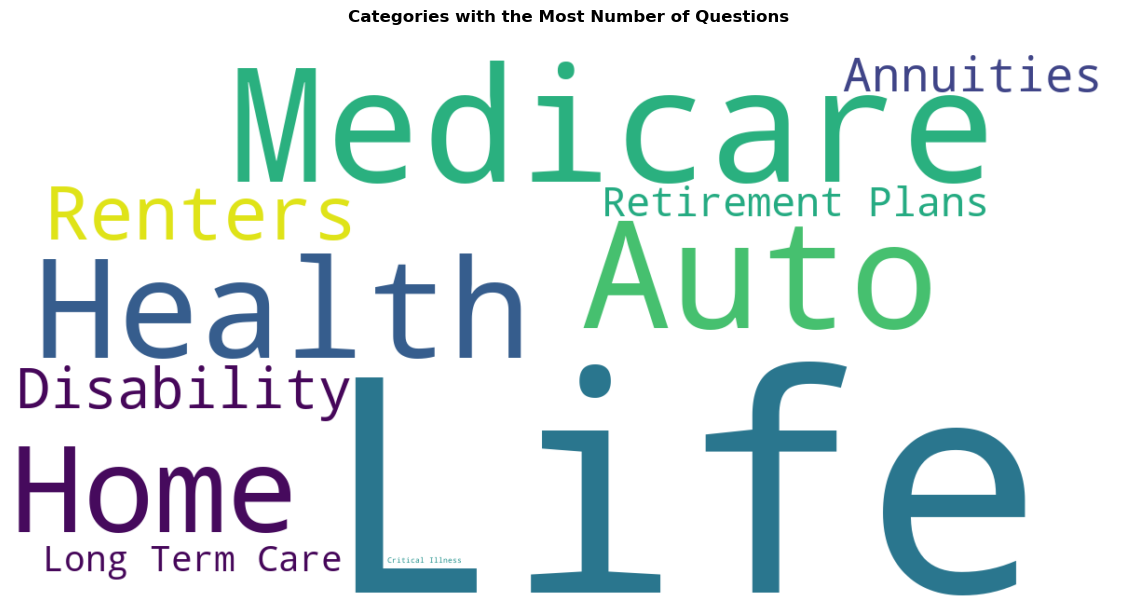

In [70]:

# Size category labels by their number of unique questions.
category_labels = (
    category_summary["Insurance category"]
    .str.replace("-insurance", "", regex=False)
    .str.replace("-", " ", regex=False)
    .str.title()
)

category_frequencies = dict(zip(
    category_labels,
    category_summary["Questions"]
))

cloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    colormap="viridis",
    relative_scaling=1,
    prefer_horizontal=1,
    random_state=530
).generate_from_frequencies(category_frequencies)

fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
ax.imshow(cloud, interpolation="bilinear")
ax.axis("off")
ax.set_title(
    "Number of Questions by Insurance Category",
    fontweight="bold",
    pad=15
)

figures["figure1_category_wordcloud"] = fig
plt.show()

Life insurance is the largest category, followed by Medicare, auto, and health insurance. Critical illness and other insurance account for relatively few questions. This imbalance means that strong overall clustering results may conceal weaker representation of smaller categories, which the later heatmaps examine more closely.

## Split the Data

I randomly divide the unique questions into 60% training, 20% validation, and 20% test data. They have 10119, 3373, and 3373 questions respectively. Training data are used to fit the models, validation data to compare settings, and test data for final evaluation. A fixed random seed makes the split reproducible.

In [71]:
# Reserve 20% for testing.
train_valid, test_data = train_test_split(
    questions_clean,
    test_size=0.20,
    random_state=530
)

# Use 60% for training and 20% for validation.
train_data, valid_data = train_test_split(
    train_valid,
    test_size=0.25,
    random_state=530
)

split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test"],
    "Questions": [
        len(train_data),
        len(valid_data),
        len(test_data)
    ]
})

## Convert Questions into Word Counts

CountVectorizer represents each question by its word counts. I exclude standard English stopwords, the common question words “does” and “did,” and words appearing in fewer than two training questions. The vocabulary is learned from training data only and then applied to validation data to prevent information leakage.

In [72]:

# Remove standard English stopwords and common question wording.
custom_stop_words = sorted(
    set(ENGLISH_STOP_WORDS) | {"does", "did"}
)

vectorizer = CountVectorizer(
    stop_words=custom_stop_words,
    min_df=2
)
X_train = vectorizer.fit_transform(train_data["question"])
X_valid = vectorizer.transform(valid_data["question"])

Both the training and validation vocabularies contain 1,616 words. Each matrix row represents a question, and each column represents a retained word.

## Reduce the Number of Features

The word-count matrix contains many features and mostly zeros. TruncatedSVD summarizes patterns in word usage using fewer numerical features, making it suitable for this sparse text representation. I begin with 50 components and compare alternative settings during tuning. SVD is fitted on training data only.

In [73]:

# Learn a smaller representation of the training word-count matrix.
svd = TruncatedSVD(n_components=50, random_state=530)

X_train_svd = svd.fit_transform(X_train)
X_valid_svd = svd.transform(X_valid)

With 50 components, 59.1% of the variance is explained.

## Compare the Number of Clusters

To check whether fewer clusters combine related topics more effectively, I compare 6, 9, 12, and 15 clusters using 25 SVD components. Each model is fitted on training questions and evaluated on validation questions. I compare silhouette scores and cluster sizes; the existing category labels are not used to fit or select the clusters. Scores use the same reproducible sample of 2,000 validation questions.


In [ ]:

# Compare cluster counts using the same 25-component representation.
cluster_scan_svd = TruncatedSVD(n_components=25, random_state=530)
cluster_scan_train = cluster_scan_svd.fit_transform(X_train)
cluster_scan_valid = cluster_scan_svd.transform(X_valid)

results = []

for k in [6, 9, 12, 15]:
    model = MiniBatchKMeans(
        n_clusters=k,
        random_state=530,
        n_init=10,
        batch_size=256
    )

    model.fit(cluster_scan_train)
    valid_clusters = model.predict(cluster_scan_valid)

    score = silhouette_score(
        cluster_scan_valid,
        valid_clusters,
        sample_size=2000,
        random_state=530
    )

    sizes = pd.Series(valid_clusters).value_counts()

    results.append({
        "Clusters": k,
        "Validation silhouette": score,
        "Calinski-Harabasz": calinski_harabasz_score(
            cluster_scan_valid, valid_clusters
        ),
        "Davies-Bouldin": davies_bouldin_score(
            cluster_scan_valid, valid_clusters
        ),
        "Smallest validation cluster": sizes.min(),
        "Largest validation cluster": sizes.max()
    })

cluster_results = pd.DataFrame(results)

## Compare the Number of SVD Components

I compare 25, 50, and 100 SVD components for the two leading cluster counts from the initial comparison: 12 and 15. This checks whether changing the numerical representation affects validation separation. All transformations and models are fitted on training data and evaluated on validation data.


In [75]:
# Compare feature dimensions for the two leading cluster counts.
tuning_results = []

for components in [25, 50, 100]:
    svd_model = TruncatedSVD(
        n_components=components,
        random_state=530
    )

    train_reduced = svd_model.fit_transform(X_train)
    valid_reduced = svd_model.transform(X_valid)

    for k in [12, 15]:
        model = MiniBatchKMeans(
            n_clusters=k,
            random_state=530,
            n_init=10,
            batch_size=256
        )

        model.fit(train_reduced)
        valid_clusters = model.predict(valid_reduced)

        score = silhouette_score(
            valid_reduced,
            valid_clusters,
            sample_size=2000,
            random_state=530
        )

        sizes = pd.Series(valid_clusters).value_counts()

        tuning_results.append({
            "SVD components": components,
            "Clusters": k,
            "Validation silhouette": score,
            "Smallest validation cluster": sizes.min(),
            "Largest validation cluster": sizes.max()
        })

tuning_results = pd.DataFrame(tuning_results)

### Figure 2. Validation Results Across Model Settings

The left panel compares 6, 9, 12, and 15 clusters using 25 SVD components. The right panel compares 25, 50, and 100 components for the 12- and 15-cluster models. Higher silhouette scores indicate greater separation within the evaluated representation. I consider these scores alongside cluster contents and stability.


In [ ]:
# Visualize the existing validation results without fitting new models.
fig, axes = plt.subplots(
    1, 2, figsize=(12, 4.5), layout="constrained"
)

initial = cluster_results.sort_values("Clusters")

axes[0].plot(
    initial["Clusters"],
    initial["Validation silhouette"],
    marker="o",
    color="#245B78"
)

axes[0].set_xticks(initial["Clusters"])
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Validation silhouette score")
axes[0].set_title("Cluster counts with 25 SVD components")

for k, color in [(12, "#245B78"), (15, "#AE783B")]:
    subset = tuning_results[
        tuning_results["Clusters"].eq(k)
    ].sort_values("SVD components")

    axes[1].plot(
        subset["SVD components"],
        subset["Validation silhouette"],
        marker="o",
        color=color,
        label=f"{k} clusters"
    )

axes[1].set_xticks([25, 50, 100])
axes[1].set_xlabel("SVD components")
axes[1].set_ylabel("Validation silhouette score")
axes[1].set_title("Component counts for the leading models")
axes[1].legend()

for ax in axes:
    ax.set_ylim(0, 0.55)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

figures["figure2_model_tuning"] = fig
plt.show()

**Table 2. Internal validation metrics by cluster count.** Silhouette is calculated on a reproducible sample of 2,000 validation questions; Calinski–Harabasz and Davies–Bouldin use all validation questions in the same 25-component space. Higher silhouette and Calinski–Harabasz values, and lower Davies–Bouldin values, indicate better separation under each metric. These scores describe feature-space separation, not agreement with the original category labels.

In [ ]:
# Compare three internal metrics for the candidate cluster counts.
metric_table = cluster_results[[
    "Clusters",
    "Validation silhouette",
    "Calinski-Harabasz",
    "Davies-Bouldin",
    "Smallest validation cluster",
    "Largest validation cluster"
]].copy()

metric_table["Validation silhouette"] = metric_table["Validation silhouette"].round(3)
metric_table["Calinski-Harabasz"] = metric_table["Calinski-Harabasz"].round(1)
metric_table["Davies-Bouldin"] = metric_table["Davies-Bouldin"].round(3)
display(HTML(metric_table.to_html(index=False)))

At 25 components, the silhouette score increased from 0.297 with 6 clusters to 0.406 with 9, 0.433 with 12, and 0.460 with 15. Davies–Bouldin also favored 15 clusters, while Calinski–Harabasz was highest with 9, so the metrics do not identify one universally best value. The 9-cluster model still separated an auto-focused group while mixing car, home, and disability terms in another; 6 clusters created very broad groups. I retain 15 as the primary model because it had the strongest silhouette, lowest Davies–Bouldin, and interpretable topics, while noting 9 clusters as a broader alternative. This is a reasoned choice among the tested settings, not a proven global optimum.


## Compare Word-Count and TF-IDF Representations

CountVectorizer is a bag-of-words method: it records which retained words occur and how often. I also test TF-IDF, which weights words by their frequency in a question and how distinctive they are across the corpus ([scikit-learn guide](https://scikit-learn.org/stable/modules/feature_extraction.html#tfidf-term-weighting)). For a focused comparison, both representations use 25 SVD components and 15 clusters; I compare validation silhouette scores and do not use the test set to select between them. TF-IDF reweights words but does not combine synonyms such as “car” and “auto.”

In [ ]:
# Compare both word representations with the same model settings.
tfidf_vectorizer = TfidfVectorizer(
    stop_words=custom_stop_words,
    min_df=2
)
X_train_tfidf = tfidf_vectorizer.fit_transform(train_data["question"])
X_valid_tfidf = tfidf_vectorizer.transform(valid_data["question"])

tfidf_svd = TruncatedSVD(n_components=25, random_state=530)
train_tfidf_reduced = tfidf_svd.fit_transform(X_train_tfidf)
valid_tfidf_reduced = tfidf_svd.transform(X_valid_tfidf)

tfidf_model = MiniBatchKMeans(
    n_clusters=15,
    random_state=530,
    n_init=10,
    batch_size=256
)
tfidf_model.fit(train_tfidf_reduced)
tfidf_valid_clusters = tfidf_model.predict(valid_tfidf_reduced)

tfidf_validation_silhouette = silhouette_score(
    valid_tfidf_reduced,
    tfidf_valid_clusters,
    sample_size=2000,
    random_state=530
)

count_validation_silhouette = tuning_results.loc[
    tuning_results["SVD components"].eq(25)
    & tuning_results["Clusters"].eq(15),
    "Validation silhouette"
].iloc[0]

representation_comparison = pd.DataFrame({
    "Representation": ["Word counts", "TF-IDF weights"],
    "Validation silhouette": [
        round(count_validation_silhouette, 3),
        round(tfidf_validation_silhouette, 3)
    ],
    "SVD components": [25, 25],
    "Clusters": [15, 15]
})
display(HTML(representation_comparison.to_html(index=False)))

With these settings, word counts scored 0.460 and TF-IDF scored 0.295 on validation data. In this comparison, reweighting common and distinctive words reduced separation, so I retain word counts for the final model. This is a comparison of two bag-of-words representations, not a semantic synonym model. Stemming or lemmatization can normalize word forms, while matching synonyms such as “car” and “auto” would require a documented synonym map or a semantic representation; those changes are beyond this project’s scope.

## Inspect the Cluster Contents

I examine frequent words and one example training question from each cluster. Word frequencies are calculated from the original word-count matrix after assigning questions to groups. The example is the first listed question in each cluster, rather than a selected representative question.

**Table 3. Training cluster sizes, frequent words, and example questions.**

In [90]:
# Fit the leading configuration and inspect its training clusters.
selected_svd = TruncatedSVD(n_components=25, random_state=530)
train_reduced = selected_svd.fit_transform(X_train)
valid_reduced = selected_svd.transform(X_valid)

selected_model = MiniBatchKMeans(
    n_clusters=15,
    random_state=530,
    n_init=10,
    batch_size=256
)

train_clusters = selected_model.fit_predict(train_reduced)

clustered_train = train_data.copy()
clustered_train["cluster"] = train_clusters + 1

words = vectorizer.get_feature_names_out()
cluster_summary = []

for cluster in range(1, 16):
    mask = train_clusters == cluster - 1
    word_counts = X_train[mask].sum(axis=0).A1
    top_words = words[word_counts.argsort()[-8:][::-1]]

    cluster_summary.append({
        "Cluster": cluster,
        "Training questions": int(mask.sum()),
        "Frequent words": ", ".join(top_words),
        "Example question": clustered_train.loc[
            clustered_train["cluster"].eq(cluster), "question"
        ].iloc[0]
    })

cluster_summary = pd.DataFrame(cluster_summary)
display(HTML(cluster_summary.to_html(index=False)))

Cluster,Training questions,Frequent words,Example question
1,779,"car, insurance, cover, drive, affect, need, cost, cheap",Can I Get USAA Car Insurance ?
2,1012,"medicare, cover, covered, advantage, plan, insurance, best, supplement",Is Transcranial Magnetic Stimulation Covered By Medicare ?
3,250,"life, insurance, term, policy, year, buy, best, cash",Which Company Is Best For Term Life Insurance ?
4,462,"home, insurance, cover, need, cost, damage, claim, owners",Can You Write Off Home Insurance On Your Taxes ?
5,2347,"life, insurance, policy, buy, best, good, cash, work",Why Is Whole Life Insurance More Expensive ?
6,332,"plan, retirement, medigap, qualified, best, save, pension, savings",What Is The Least Expensive Medigap Plan ?
7,824,"insurance, renters, cover, illness, critical, need, medigap, cost",Does Renters Insurance Cover Pet Damage ?
8,771,"annuities, medigap, annuity, variable, ira, roth, fixed, 401k",What Are The Different Kinds Of Annuities ?
9,188,"pay, medicare, home, nursing, care, hospital, wheelchair, surgery",Will Medicare Pay For Foot Orthotics ?
10,364,"long, insurance, term, care, buy, cover, best, need",Can I Buy Long Term Care Insurance For My Mother ?


Several clusters have recognizable themes, including car insurance (1), Medicare (2), life insurance (5), health insurance (11), and disability insurance (12). Clusters 1 and 14 emphasize “car” and “auto,” respectively, while clusters 7 and 8 contain more mixed terminology. These patterns suggest that the model separates both insurance subjects and differences in wording.

### Figure 3. Frequent Words in Selected Training Clusters

I examine clusters 1 and 14 to compare groups emphasizing “car” and “auto,” and clusters 7 and 8 to inspect mixed vocabulary. Each panel shows the eight words appearing in the largest percentage of that cluster’s training questions. These selected examples do not summarize every cluster. Questions can contain several words, so percentages do not sum to 100%.

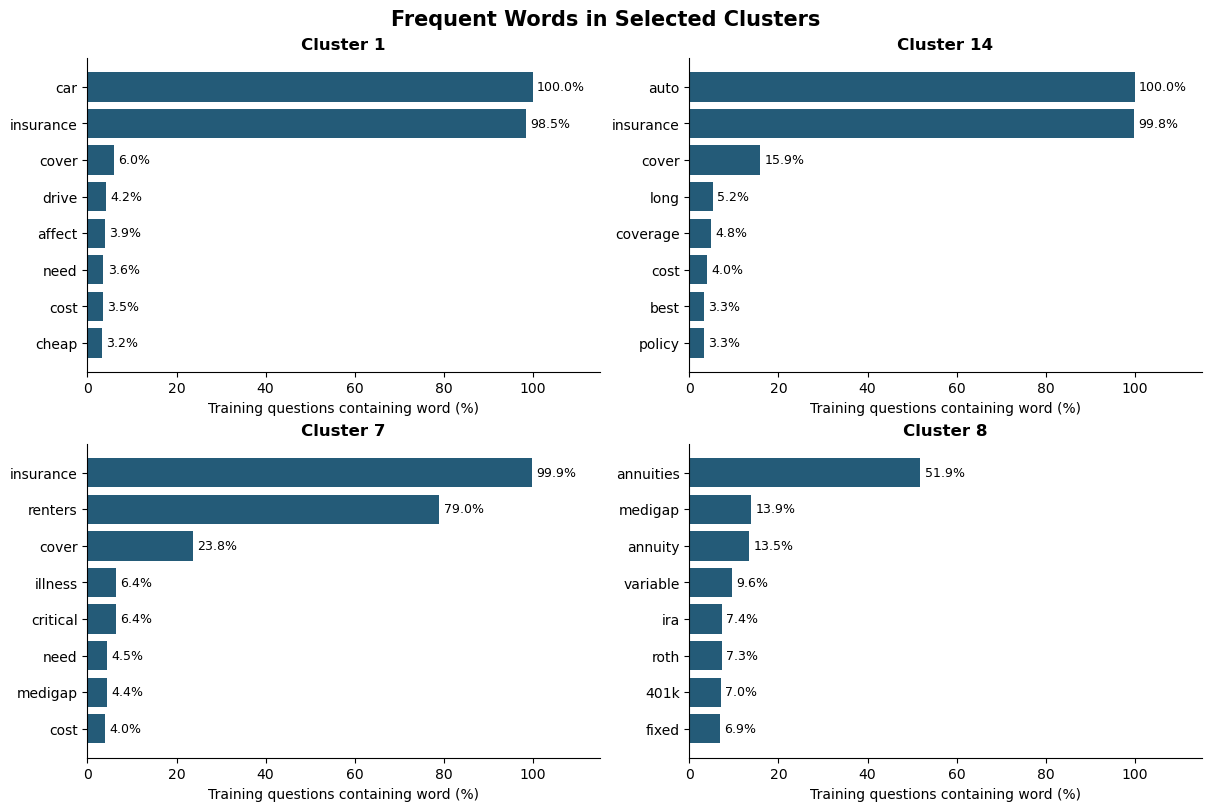

In [78]:
# Compare word presence within four selected training clusters.
fig, axes = plt.subplots(
    2, 2, figsize=(12, 8), layout="constrained"
)

for ax, cluster in zip(axes.flat, [1, 14, 7, 8]):
    mask = train_clusters == cluster - 1

    percentages = (
        100 * (X_train[mask] > 0).sum(axis=0).A1
        / mask.sum()
    )

    top_indices = percentages.argsort()[-8:][::-1]

    bars = ax.barh(
        words[top_indices],
        percentages[top_indices],
        color="#245B78"
    )

    ax.invert_yaxis()
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)
    ax.set_xlim(0, 115)
    ax.set_xlabel("Training questions containing word (%)")
    ax.set_title(f"Cluster {cluster}", fontweight="bold")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Frequent Words in Selected Clusters",
    fontsize=15,
    fontweight="bold"
)

figures["figure3_cluster_words"] = fig
plt.show()

Every training question in cluster 1 contains “car,” while every question in cluster 14 contains “auto,” illustrating how wording can separate questions about the same subject. Cluster 7 emphasizes renters insurance but also includes “critical” and “illness.” Cluster 8 combines annuity terminology with “medigap,” “IRA,” and “Roth.” The model therefore identifies recognizable topics while also separating synonyms or combining vocabulary from different categories.

## Inspect a Simpler Alternative

I inspect the 12-cluster alternative using the same 25-component representation to assess whether fewer groups produce clearer topics. Category labels remain excluded from model fitting.

In [91]:
# Inspect the simpler model using the same reduced training data.
alternative_model = MiniBatchKMeans(
    n_clusters=12,
    random_state=530,
    n_init=10,
    batch_size=256
)

alternative_clusters = alternative_model.fit_predict(train_reduced)
alternative_summary = []

for cluster in range(1, 13):
    mask = alternative_clusters == cluster - 1
    word_counts = X_train[mask].sum(axis=0).A1
    top_words = words[word_counts.argsort()[-8:][::-1]]

    alternative_summary.append({
        "Cluster": cluster,
        "Training questions": int(mask.sum()),
        "Frequent words": ", ".join(top_words),
        "Example question": train_data.loc[mask, "question"].iloc[0]
    })

alternative_summary = pd.DataFrame(alternative_summary)
with pd.option_context("display.max_colwidth", None):
    display(HTML(alternative_summary.to_html(index=False)))

Cluster,Training questions,Frequent words,Example question
1,209,"cover, medicare, medigap, plan, dental, care, home, drugs",Does Medicare Cover CPAP Supplies ?
2,2583,"life, insurance, policy, term, best, buy, cash, good",Why Is Whole Life Insurance More Expensive ?
3,1086,"annuities, retirement, plan, medigap, annuity, variable, 401k, ira",What Are The Different Kinds Of Annuities ?
4,381,"long, insurance, term, care, buy, cover, need, best",What Is The Difference Between Long Term Care And Disability Insurance ?
5,1152,"insurance, health, cover, cost, pay, best, buy, work",Section 125 Employer Health Insurance Plan What Is It ?
6,644,"insurance, renters, cover, need, damage, cost, apartment, buy",Does Renters Insurance Cover Pet Damage ?
7,1247,"insurance, car, home, need, cost, cover, illness, critical",Can I Get USAA Car Insurance ?
8,559,"disability, insurance, term, long, short, buy, cover, need",What Is The Best Disability Insurance Company ?
9,488,"insurance, auto, cover, long, coverage, cost, policy, best",Does auto insurance cover theft ?
10,1011,"medicare, pay, covered, advantage, plan, insurance, best, supplement",Is Transcranial Magnetic Stimulation Covered By Medicare ?


Reducing the model to 12 clusters did not consistently produce clearer topics. One group combined car, home, and critical-illness terminology, while another combined annuities, retirement, and Medigap. The alternative also retained separate groups emphasizing “car” and “auto,” so fewer clusters did not resolve the wording-based divisions.

## Check Clustering Stability

I repeat the 12- and 15-cluster models using two additional random seeds while keeping the word-count and SVD representations fixed. Adjusted Rand index (ARI) compares the resulting validation assignments with the original run. An ARI of 1 indicates identical groupings regardless of cluster numbering; values near 0 indicate agreement similar to chance. This checks sensitivity to clustering initialization.

In [87]:

# Check whether different initializations produce similar groups.
stability_results = []

for k, reference_model in [
    (12, alternative_model),
    (15, selected_model)
]:
    reference_labels = reference_model.predict(valid_reduced)

    for seed in [42, 2026]:
        model = MiniBatchKMeans(
            n_clusters=k,
            random_state=seed,
            n_init=10,
            batch_size=256
        )

        model.fit(train_reduced)
        labels = model.predict(valid_reduced)

        stability_results.append({
            "Clusters": k,
            "Random seed": seed,
            "Validation silhouette": silhouette_score(
                valid_reduced,
                labels,
                sample_size=2000,
                random_state=530
            ),
            "ARI with original model": adjusted_rand_score(
                reference_labels, labels
            )
        })

stability_results = pd.DataFrame(stability_results)

Both cluster counts produced reasonably consistent assignments across starting points. For 15 clusters, agreement with the original run ranged from 0.811 to 0.896. I retain 25 components and 15 clusters because this configuration had the highest validation silhouette score among the configurations tested with the original seed and identified several recognizable topics. The alternative seeds assess sensitivity rather than provide a basis for selecting the highest-scoring run.

## Evaluate the Selected Model on Test Data

I apply the fitted vectorizer, SVD transformation, and clustering model to the untouched test questions without refitting them. Silhouette is calculated on a reproducible sample of 2,000 test questions. ARI compares cluster assignments with the original insurance categories using all 3,373 test questions. This evaluates category agreement rather than prediction accuracy.

**Table 4. Selected model settings and final test results.**

In [92]:
# Apply the selected model to previously unused test questions.
X_test = vectorizer.transform(test_data["question"])
test_reduced = selected_svd.transform(X_test)
test_clusters = selected_model.predict(test_reduced)

test_silhouette = silhouette_score(
    test_reduced,
    test_clusters,
    sample_size=2000,
    random_state=530
)

category_agreement = adjusted_rand_score(
    test_data["category"],
    test_clusters
)

stability_15 = stability_results.loc[
    stability_results["Clusters"].eq(15)
].set_index("Random seed")["ARI with original model"]

test_results = pd.DataFrame({
    "Measure": [
        "Test questions",
        "SVD components",
        "Clusters",
        "Validation silhouette",
        "Test silhouette",
        "Test ARI vs. insurance categories",
        "Stability ARI, seed 42",
        "Stability ARI, seed 2026"
    ],
    "Value": [
        f"{len(test_data):,}",
        "25",
        "15",
        "0.460",
        f"{test_silhouette:.3f}",
        f"{category_agreement:.3f}",
        f"{stability_15.loc[42]:.3f}",
        f"{stability_15.loc[2026]:.3f}"
    ]
})
display(HTML(test_results.to_html(index=False)))

# Retain the assignments for the final tables and figures.
clustered_test = test_data.copy()
clustered_test["cluster"] = test_clusters + 1

Measure,Value
Test questions,"3,373"
SVD components,25
Clusters,15
Validation silhouette,0.460
Test silhouette,0.476
Test ARI vs. insurance categories,0.796
"Stability ARI, seed 42",0.811
"Stability ARI, seed 2026",0.896


The selected model achieved a test silhouette score of 0.476, compared with 0.460 on validation data, suggesting that cluster separation was maintained on unseen questions. Its ARI against the original categories was 0.796, indicating substantial agreement even though category labels were excluded from training. The two alternate starting points had ARIs of 0.811 and 0.896 relative to the original model’s assignments, showing reasonably consistent but not identical clusters. The cluster-composition figure below shows where the model’s results align with the categories and where they differ.

## Compare Clusters with Insurance Categories

For each test cluster, I report its size, most common original category, and the percentage belonging to that category. This identifies concentrated groups and groups containing a mixture of categories.

In [82]:
# Count the original insurance categories within each test cluster.
category_counts = pd.crosstab(
    clustered_test["cluster"],
    clustered_test["category"]
)

cluster_comparison = pd.DataFrame({
    "Test questions": category_counts.sum(axis=1),
    "Most common category": category_counts.idxmax(axis=1),
    "Most common category (%)": (
        100 * category_counts.max(axis=1)
        / category_counts.sum(axis=1)
    ).round(1)
})

cluster_comparison = (
    cluster_comparison.rename_axis("Cluster").reset_index()
)

Most clusters are strongly concentrated within one category. Clusters 7 and 8 are more mixed: renters insurance accounts for 69.3% of cluster 7, while annuities account for 57.6% of cluster 8. However, a concentrated cluster does not necessarily contain all questions from its dominant category.

### Figure 4. Cluster Composition and Category Distribution

Panel A shows the category composition of each cluster; rows total approximately 100%. Panel B shows where each category’s questions were assigned; columns total approximately 100%. Both panels use the same test questions and assignments. All nonzero percentages are labeled, with small rounding differences possible. Cluster rows are arranged in a topic-oriented order for readability; the original cluster IDs are unchanged.


In [ ]:
# Arrange related topic groups together; cluster IDs remain unchanged.
cluster_order = [1, 14, 2, 9, 3, 5, 4, 13, 8, 6, 10, 11, 12, 15, 7]
category_counts = category_counts.reindex(cluster_order)

# Compare cluster composition with category distribution.
within_cluster = category_counts.div(
    category_counts.sum(axis=1), axis=0
) * 100

within_category = category_counts.div(
    category_counts.sum(axis=0), axis=1
) * 100

category_labels = [
    category.replace("-insurance", "").replace("-", " ").title()
    for category in category_counts.columns
]

fig, axes = plt.subplots(
    1, 2, figsize=(19, 8), layout="constrained"
)

for ax, values, title in zip(
    axes,
    [within_cluster, within_category],
    [
        "A. Category composition within clusters\nRows total 100%",
        "B. Distribution of categories across clusters\nColumns total 100%"
    ]
):
    image = ax.imshow(
        values,
        cmap="Blues",
        vmin=0,
        vmax=100,
        aspect="auto"
    )

    ax.set_xticks(
        range(len(category_labels)),
        category_labels,
        rotation=55,
        ha="right",
        fontsize=9
    )
    ax.set_yticks(range(len(values)), values.index)
    ax.set_xlabel("Original insurance category")
    ax.set_ylabel("Cluster")
    ax.set_title(title, fontsize=12, fontweight="bold", pad=12)

    for row in range(values.shape[0]):
        for column in range(values.shape[1]):
            value = values.iloc[row, column]

            if value > 0:
                ax.text(
                    column, row, f"{value:.1f}%",
                    ha="center", va="center",
                    color="white" if value > 50 else "black",
                    fontsize=7
                )

fig.colorbar(
    image,
    ax=axes,
    label="Percentage within the indicated row or column",
    shrink=0.85
)

figures["figure4_category_heatmaps"] = fig
figures["figure4_category_heatmaps"] = fig
plt.show()

Clusters 1 and 14 are each over 99% auto insurance, but contain 57.5% and 37.9% of all auto-insurance test questions, respectively. Their training vocabulary emphasizes “car” and “auto,” illustrating how wording can divide a single subject.

Conversely, a category can remain together without forming a distinct group. All 33 critical-illness test questions appear in cluster 7, but constitute only 11.4% of that cluster, which is dominated by renters insurance. The panels therefore distinguish categories that form distinct groups from those that are divided or combined with other topics.

## Discussion

Unsupervised clustering organized many insurance questions into recognizable topics. The selected model achieved a test silhouette score of 0.476 and an ARI of 0.796 against the original categories, with reasonably consistent assignments across random starting points. During validation, silhouette and Davies–Bouldin favored 15 clusters, while Calinski–Harabasz favored 9. I kept 15 because it separated more focused topics, but the alternative metrics show that the choice depends partly on the desired level of detail.

The vocabulary charts and heatmaps show why these scores do not tell the whole story. Some subjects form distinct groups, while others are divided by wording or combined with different categories. In particular, separating “car” from “auto” shows that numerical separation does not necessarily produce the most useful organization of insurance topics.

These results suggest that clustering could support an initial organization of insurance FAQs, followed by human review. Word counts capture vocabulary rather than meaning or word order, and unequal category sizes can obscure smaller topics in overall scores. The selected configuration is the strongest candidate from the settings tested, rather than a proven global optimum. A validation comparison of TF-IDF and word counts checks one alternative weighting scheme. TF-IDF does not merge synonyms; future work could test a documented synonym map or word normalization and then verify whether it improves topic coherence.


## Export Tables and Figures

I save the report tables as CSV files and figures as high-resolution PNG files in separate folders. These exports make the results easy to include in a presentation or share without showing notebook code.

In [ ]:
# Export the result tables and figures for presentation use.
tables = {
    "data_quality_checks": quality_summary,
    "category_summary": category_summary,
    "cluster_count_validation": cluster_results,
    "svd_and_cluster_validation": tuning_results,
    "selected_15_cluster_summary": cluster_summary,
    "alternative_12_cluster_summary": alternative_summary,
    "representation_comparison": representation_comparison,
    "stability_results": stability_results,
    "final_test_results": test_results,
    "test_cluster_category_summary": cluster_comparison
}

for name, table in tables.items():
    table.to_csv(TABLE_DIR / f"{name}.csv", index=False)

for name, figure in figures.items():
    figure.savefig(
        FIGURE_DIR / f"{name}.png",
        dpi=300,
        bbox_inches="tight"
    )